# Figure S5A — Throughput across versions and hardware

Residues predicted per second (log scale) by metapredict V1, V2 and V3 on each hardware configuration, predicting the human reference proteome (UniProt UP000005640, 20,652 sequences).

**How it is made.** Same runs as Figure 1E: every TSV in `data/benchmarks/proteome/`, written by `benchmarks/proteome/benchmark_metapredict.py` with metapredict 3.1.0 at its default per-device batch size (warmup and file I/O excluded from the timing). Repeat runs of one configuration are summarised by their median.

**Output:** `figures/figure_S05A.pdf`

In [1]:
import matplotlib.pyplot as plt

from figtools import apply_style, save_panel
from perf_plots import (grouped_version_bars, hardware_groups, hardware_label, median_by,
                        proteome_rows, version_legend)

apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
rows = proteome_rows()
groups = hardware_groups(rows)
throughput = median_by(rows, lambda r: (r['network_version'], hardware_label(r)), 'residues_per_second')

proteome: 12 rows from 12 files; metapredict (version, commit): [('3.1.0+6.ga1b28a7.dirty', '7dcf52c+dirty'), ('3.1.0+7.g7dcf52c.dirty', '7dcf52c+dirty')]


Wrote figures/figure_S05A.pdf


PosixPath('figures/figure_S05A.pdf')

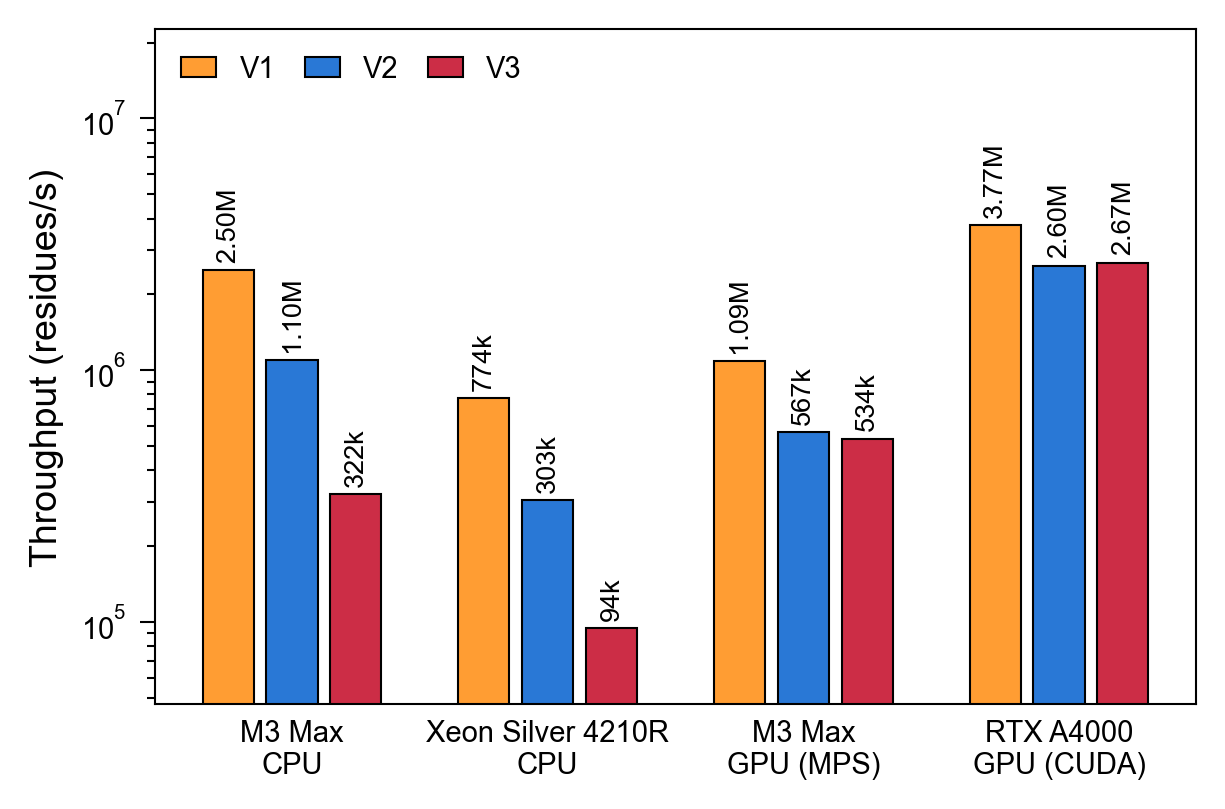

In [3]:
# bars start at the bottom of the log axis, not at 0 (see grouped_version_bars)
y_floor = min(throughput.values()) * 0.5
fig, ax = plt.subplots(figsize=(4.2, 2.8), dpi=150)
grouped_version_bars(ax, groups, throughput, label_rotation=90, bottom=y_floor,
                     label_fmt=lambda v: f'{v / 1e6:.2f}M' if v >= 1e6 else f'{v / 1e3:.0f}k')
ax.set_yscale('log')
ax.set_ylim(y_floor, max(throughput.values()) * 6)
ax.set_ylabel('Throughput (residues/s)', fontsize=9)
version_legend(ax, loc='upper left', ncol=3)
plt.tight_layout()
save_panel(fig, 'figure_S05A')